In [1]:
from pyspark.sql import SparkSession

spark = SparkSession.builder.getOrCreate()

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/14 18:04:50 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/11/14 18:04:51 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.


In [2]:
from typing import Any, List, Optional, Tuple
from pyspark.sql import DataFrame, Window
from pyspark.sql import functions as F

In [3]:
data = [
    (5, 5, 181344,   7515290),
    (5, 4, 161337,   5423364),
    (5, 3, 319548,   3700403),
    (5, 2, 452825,   4909977),
    (5, 1, 1461203,  6720114),
    (5, 0, 0,              0),

    (4, 5, 64711,    4495745),
    (4, 4, 1188065,  9066067),
    (4, 3, 1677696, 14722180),
    (4, 2, 6401425, 27605785),
    (4, 1,10763213, 44461895),
    (4, 0,       0,     9052),

    (3, 5, 40517,    2458981),
    (3, 4, 788068,   8181737),
    (3, 3,2101245,  16275768),
    (3, 2,9536756,  34032015),
    (3, 1,18874024, 64400631),
    (3, 0,       0,      968),

    (2, 5, 63994,    2082020),
    (2, 4, 607937,   7706722),
    (2, 3,2093645,  14271236),
    (2, 2,6326701,  28961055),
    (2, 1,18274197, 60398807),
    (2, 0,       0,     1588),

    (1, 5, 56959,    2215100),
    (1, 4, 952746,   7931608),
    (1, 3,2059018,  17703350),
    (1, 2,3952309,  39509761),
    (1, 1,13391808, 87938607),
    (1, 0,       0,        0),

    (0, 5,      0,    308718),
    (0, 4,      0,    857035),
    (0, 3, 429189,  2867964),
    (0, 2,1018541,  4458697),
    (0, 1,6408843, 11914368),
    (0, 0,      0,        0),
]

df = spark.createDataFrame(
    data,
    ["band_1", "band_2", "saldo_over", "producao"]
)

df = (df
      .withColumn('bad_rate', F.when(F.col('producao') != 0, 100 * F.col('saldo_over') / F.col('producao')).otherwise(0))
)

df.show(36, truncate=False)

+------+------+----------+--------+------------------+
|band_1|band_2|saldo_over|producao|bad_rate          |
+------+------+----------+--------+------------------+
|5     |5     |181344    |7515290 |2.4130006959145955|
|5     |4     |161337    |5423364 |2.9748510334176355|
|5     |3     |319548    |3700403 |8.635491863994273 |
|5     |2     |452825    |4909977 |9.222548292996077 |
|5     |1     |1461203   |6720114 |21.743723395168594|
|5     |0     |0         |0       |0.0               |
|4     |5     |64711     |4495745 |1.4393832390404704|
|4     |4     |1188065   |9066067 |13.104524817652461|
|4     |3     |1677696   |14722180|11.395703625414171|
|4     |2     |6401425   |27605785|23.188708453680995|
|4     |1     |10763213  |44461895|24.207724389614974|
|4     |0     |0         |9052    |0.0               |
|3     |5     |40517     |2458981 |1.6477150494452784|
|3     |4     |788068    |8181737 |9.632037793441661 |
|3     |3     |2101245   |16275768|12.910266354251302|
|3     |2 

In [ ]:
import numpy as np
import pandas as pd
from scipy.optimize import Bounds, LinearConstraint, milp
from scipy.sparse import lil_matrix


def assign_monotone_nr(
    source_df,
    approach="group_weighted",
    cutoffs=(1, 2, 5, 8, 10, 12, 15, 18, 20),
    overflow_nr=100,
    time_limit=60,
):
    """
    Assign monotone NR labels using one of two bad-rate criteria:

      - "group_weighted" checks one weighted bad rate per NR_cutoff:
        total saldo_over divided by total producao for all cells assigned to
        that cutoff. The group's weighted rate must fall within its cutoff
        interval.

      - "ordered_prefix" orders cells within each NR_cutoff by individual
        bad_rate and checks the cumulative weighted rate after each cell is
        added. If some prefix rates cannot meet their cutoff intervals while
        preserving monotone labels, a two-stage solve first minimizes total
        cutoff violation, then minimizes cell-fit cost.

    In short, "group_weighted" evaluates the whole group, while
    "ordered_prefix" evaluates the group's cumulative rate as cells are added
    in order. In both approaches, NR labels cannot decrease when either
    band_1 or band_2 decreases.

    Returns the same Spark DataFrame schema for both approaches.
    """
    if approach not in {"group_weighted", "ordered_prefix"}:
        raise ValueError("approach must be 'group_weighted' or 'ordered_prefix'")

    cutoffs = sorted(int(c) for c in cutoffs)
    if not cutoffs or len(set(cutoffs)) != len(cutoffs):
        raise ValueError("cutoffs must be a nonempty sequence of unique values")
    if overflow_nr <= cutoffs[-1]:
        raise ValueError("overflow_nr must be greater than the largest cutoff")

    nr_labels = cutoffs + [int(overflow_nr)]
    n_labels = len(nr_labels)
    lower_cutoffs = [0.0] + [float(c) for c in cutoffs]

    cells_pdf = (
        source_df
        .select("band_1", "band_2", "saldo_over", "producao", "bad_rate")
        .toPandas()
        .sort_values(["band_1", "band_2"], ascending=[False, False])
        .reset_index(drop=True)
    )
    if cells_pdf.empty:
        raise ValueError("source_df has no cells to assign")

    n_cells = len(cells_pdf)
    n_assignment_vars = n_cells * n_labels
    cell_index = {
        (int(row.band_1), int(row.band_2)): i
        for i, row in cells_pdf.iterrows()
    }
    band1_order = sorted(cells_pdf["band_1"].unique(), reverse=True)
    band2_order = sorted(cells_pdf["band_2"].unique(), reverse=True)

    bad = cells_pdf["saldo_over"].to_numpy(dtype=float)
    exposure = cells_pdf["producao"].to_numpy(dtype=float)
    total_exposure = max(float(exposure.sum()), 1.0)

    running_order = (
        cells_pdf.sort_values(
            ["bad_rate", "band_1", "band_2"],
            ascending=[True, False, False],
        ).index.tolist()
    )

    # Running mode uses nonnegative slack variables so the solver can return
    # the closest monotone solution when strict prefix cutoffs conflict.
    slack_count = 2 * n_labels * n_cells if approach == "ordered_prefix" else 0
    n_variables = n_assignment_vars + slack_count

    rows, lower_bounds, upper_bounds = [], [], []

    def add_constraint(coefficients, lb=-np.inf, ub=np.inf):
        rows.append(coefficients)
        lower_bounds.append(lb)
        upper_bounds.append(ub)

    # Exactly one NR label per cell.
    for i in range(n_cells):
        add_constraint(
            {i * n_labels + k: 1.0 for k in range(n_labels)},
            lb=1.0,
            ub=1.0,
        )

    # Moving to a lower band value cannot lower the ordinal NR label.
    for (band1, band2), i in cell_index.items():
        pos1 = band1_order.index(band1)
        pos2 = band2_order.index(band2)
        neighbors = []
        if pos1 + 1 < len(band1_order):
            neighbors.append((band1_order[pos1 + 1], band2))
        if pos2 + 1 < len(band2_order):
            neighbors.append((band1, band2_order[pos2 + 1]))

        for neighbor in neighbors:
            if neighbor in cell_index:
                j = cell_index[neighbor]
                coefficients = {
                    i * n_labels + k: float(-k)
                    for k in range(n_labels)
                }
                coefficients.update({
                    j * n_labels + k: float(k)
                    for k in range(n_labels)
                })
                add_constraint(coefficients, lb=0.0)

    def rate_constraint_coefficients(cell_ids, label_index, cutoff):
        cutoff_fraction = cutoff / 100.0
        return {
            i * n_labels + label_index:
                float(bad[i] - cutoff_fraction * exposure[i]) / total_exposure
            for i in cell_ids
        }

    if approach == "group_weighted":
        # Each assigned NR group's aggregate weighted rate is in its interval.
        all_cells = range(n_cells)
        for k, label in enumerate(nr_labels):
            add_constraint(
                rate_constraint_coefficients(
                    all_cells, k, lower_cutoffs[k]
                ),
                lb=0.0,
            )
            if k < len(cutoffs):
                add_constraint(
                    rate_constraint_coefficients(all_cells, k, cutoffs[k]),
                    ub=0.0,
                )
    else:
        # Every prefix, restricted to cells assigned to this NR and ordered by
        # bad_rate, must stay within the cutoff interval when possible.
        for k, label in enumerate(nr_labels):
            for prefix_end in range(n_cells):
                prefix_cells = running_order[:prefix_end + 1]

                lower_coefficients = rate_constraint_coefficients(
                    prefix_cells, k, lower_cutoffs[k]
                )
                lower_slack = (
                    n_assignment_vars + k * n_cells + prefix_end
                )
                lower_coefficients[lower_slack] = 1.0
                add_constraint(lower_coefficients, lb=0.0)

                if k < len(cutoffs):
                    upper_coefficients = rate_constraint_coefficients(
                        prefix_cells, k, cutoffs[k]
                    )
                    upper_slack = (
                        n_assignment_vars
                        + n_labels * n_cells
                        + k * n_cells
                        + prefix_end
                    )
                    upper_coefficients[upper_slack] = -1.0
                    add_constraint(upper_coefficients, ub=0.0)

    # Minimize exposure-weighted distance to bucket midpoints.
    centers = [
        (lower_cutoffs[k] + cutoff) / 2.0
        for k, cutoff in enumerate(cutoffs)
    ]
    centers.append(float(cutoffs[-1]))  # overflow bucket

    objective = np.zeros(n_variables, dtype=float)
    for i in range(n_cells):
        if exposure[i] > 0:
            rate_fraction = bad[i] / exposure[i]
            for k, center in enumerate(centers):
                objective[i * n_labels + k] = (
                    exposure[i] / total_exposure
                    * (rate_fraction - center / 100.0) ** 2
                )
        else:
            # No observed risk: choose the lowest label compatible with neighbors.
            for k in range(n_labels):
                objective[i * n_labels + k] = k * 1e-6

    constraint_matrix = lil_matrix((len(rows), n_variables), dtype=float)
    for row_idx, coefficients in enumerate(rows):
        for col_idx, value in coefficients.items():
            constraint_matrix[row_idx, col_idx] = value

    integrality = np.concatenate([
        np.ones(n_assignment_vars, dtype=int),
        np.zeros(slack_count, dtype=int),
    ])
    variable_lbs = np.zeros(n_variables)
    variable_ubs = np.concatenate([
        np.ones(n_assignment_vars),
        np.full(slack_count, np.inf),
    ])
    base_constraints = LinearConstraint(
        constraint_matrix.tocsr(),
        np.asarray(lower_bounds),
        np.asarray(upper_bounds),
    )
    solver_options = {"time_limit": time_limit}

    if slack_count:
        # Stage 1: find the smallest possible total cutoff violation.
        slack_objective = np.zeros(n_variables, dtype=float)
        slack_objective[n_assignment_vars:] = 1.0
        slack_solution = milp(
            c=slack_objective,
            integrality=integrality,
            bounds=Bounds(variable_lbs, variable_ubs),
            constraints=base_constraints,
            options=solver_options,
        )
        if not slack_solution.success:
            raise RuntimeError(
                f"{approach} slack minimization failed: "
                f"{slack_solution.message}"
            )

        minimum_slack = float(
            slack_solution.x[n_assignment_vars:].sum()
        )
        slack_tolerance = 1e-7

        # Stage 2: preserve the minimum slack, then minimize cell-fit cost.
        slack_budget = lil_matrix((1, n_variables), dtype=float)
        for slack_idx in range(n_assignment_vars, n_variables):
            slack_budget[0, slack_idx] = 1.0
        fit_solution = milp(
            c=objective,
            integrality=integrality,
            bounds=Bounds(variable_lbs, variable_ubs),
            constraints=[
                base_constraints,
                LinearConstraint(
                    slack_budget.tocsr(),
                    -np.inf,
                    minimum_slack + slack_tolerance,
                ),
            ],
            options=solver_options,
        )
        if not fit_solution.success:
            raise RuntimeError(
                f"{approach} fit minimization failed: "
                f"{fit_solution.message}"
            )
        solution = fit_solution
    else:
        # Aggregate-rate approach has hard group cutoff constraints and no slack.
        solution = milp(
            c=objective,
            integrality=integrality,
            bounds=Bounds(variable_lbs, variable_ubs),
            constraints=base_constraints,
            options=solver_options,
        )
        if not solution.success:
            raise RuntimeError(
                f"{approach} assignment failed: {solution.message}"
            )

    chosen = np.argmax(
        solution.x[:n_assignment_vars].reshape(n_cells, n_labels),
        axis=1,
    )
    cells_pdf["NR_cutoff"] = [nr_labels[k] for k in chosen]
    cells_pdf["NR_index"] = [int(k + 1) for k in chosen]

    assignments = spark.createDataFrame(
        cells_pdf[["band_1", "band_2", "NR_cutoff", "NR_index"]]
    )
    result = source_df.join(
        assignments,
        ["band_1", "band_2"],
        "left",
    )

    nr_stats = (
        result.groupBy("NR_cutoff")
        .agg(
            F.sum("saldo_over").alias("_nr_saldo_over"),
            F.sum("producao").alias("_nr_producao"),
        )
        .withColumn(
            "nr_weighted_bad_rate",
            F.when(
                F.col("_nr_producao") > 0,
                100.0 * F.col("_nr_saldo_over") / F.col("_nr_producao"),
            ),
        )
        .select("NR_cutoff", "nr_weighted_bad_rate")
    )
    result = result.join(nr_stats, "NR_cutoff", "left")

    running_window = (
        Window.partitionBy("NR_cutoff")
        .orderBy(
            F.col("bad_rate").asc(),
            F.col("band_1").desc(),
            F.col("band_2").desc(),
        )
        .rowsBetween(Window.unboundedPreceding, Window.currentRow)
    )
    result = (
        result
        .withColumn(
            "running_saldo_over",
            F.sum("saldo_over").over(running_window),
        )
        .withColumn(
            "running_producao",
            F.sum("producao").over(running_window),
        )
        .withColumn(
            "running_bad_rate",
            F.when(
                F.col("running_producao") > 0,
                100.0 * F.col("running_saldo_over")
                / F.col("running_producao"),
            ),
        )
    )

    lower_expr = F.lit(0.0)
    for k, label in enumerate(nr_labels):
        lower_expr = F.when(
            F.col("NR_cutoff") == label,
            F.lit(lower_cutoffs[k]),
        ).otherwise(lower_expr)

    upper_expr = F.lit(None).cast("double")
    for cutoff in cutoffs:
        upper_expr = F.when(
            F.col("NR_cutoff") == cutoff,
            F.lit(float(cutoff)),
        ).otherwise(upper_expr)

    running_violation = (
        F.greatest(F.lit(0.0), lower_expr - F.col("running_bad_rate"))
        + F.when(
            upper_expr.isNotNull(),
            F.greatest(
                F.lit(0.0),
                F.col("running_bad_rate") - upper_expr,
            ),
        ).otherwise(F.lit(0.0))
    )

    return (
        result
        .withColumn(
            "running_cutoff_violation",
            F.when(
                F.col("running_bad_rate").isNotNull(),
                running_violation,
            ),
        )
        .withColumn("approach", F.lit(approach))
        .select(
            "band_1",
            "band_2",
            "saldo_over",
            "producao",
            "bad_rate",
            "NR_cutoff",
            "NR_index",
            "nr_weighted_bad_rate",
            "running_saldo_over",
            "running_producao",
            "running_bad_rate",
            "running_cutoff_violation",
            "approach",
        )
        .orderBy(F.desc("band_1"), F.desc("band_2"))
    )

In [5]:
# Both results have the same columns and types, so they can be compared directly.
group_weighted_results = assign_monotone_nr(
    df,
    approach="group_weighted",
)

print("Standard output schema:")
group_weighted_results.printSchema()

print("Group-weighted approach:")
group_weighted_results.show(100, truncate=False)

Standard output schema:
root
 |-- band_1: long (nullable = true)
 |-- band_2: long (nullable = true)
 |-- saldo_over: long (nullable = true)
 |-- producao: long (nullable = true)
 |-- bad_rate: double (nullable = true)
 |-- NR_cutoff: long (nullable = true)
 |-- NR_index: long (nullable = true)
 |-- nr_weighted_bad_rate: double (nullable = true)
 |-- running_saldo_over: long (nullable = true)
 |-- running_producao: long (nullable = true)
 |-- running_bad_rate: double (nullable = true)
 |-- running_cutoff_violation: double (nullable = true)
 |-- approach: string (nullable = false)

Group-weighted approach:


+------+------+----------+--------+------------------+---------+--------+--------------------+------------------+----------------+------------------+------------------------+--------------+
|band_1|band_2|saldo_over|producao|bad_rate          |NR_cutoff|NR_index|nr_weighted_bad_rate|running_saldo_over|running_producao|running_bad_rate  |running_cutoff_violation|approach      |
+------+------+----------+--------+------------------+---------+--------+--------------------+------------------+----------------+------------------+------------------------+--------------+
|5     |5     |181344    |7515290 |2.4130006959145955|2        |2       |1.9804539262430672  |286572            |14470016        |1.9804539262430672|0.0                     |group_weighted|
|5     |4     |161337    |5423364 |2.9748510334176355|5        |3       |2.81468056980007    |218296            |7947182         |2.746835293315291 |0.0                     |group_weighted|
|5     |3     |319548    |3700403 |8.6354918639942

In [6]:
ordered_prefix_results = assign_monotone_nr(
    df,
    approach="ordered_prefix",
)

print("Ordered-prefix approach:")
ordered_prefix_results.show(100, truncate=False)

Ordered-prefix approach:


+------+------+----------+--------+------------------+---------+--------+--------------------+------------------+----------------+------------------+------------------------+--------------+
|band_1|band_2|saldo_over|producao|bad_rate          |NR_cutoff|NR_index|nr_weighted_bad_rate|running_saldo_over|running_producao|running_bad_rate  |running_cutoff_violation|approach      |
+------+------+----------+--------+------------------+---------+--------+--------------------+------------------+----------------+------------------+------------------------+--------------+
|5     |5     |181344    |7515290 |2.4130006959145955|2        |2       |1.9804539262430672  |286572            |14470016        |1.9804539262430672|0.0                     |ordered_prefix|
|5     |4     |161337    |5423364 |2.9748510334176355|5        |3       |2.81468056980007    |218296            |7947182         |2.746835293315291 |0.0                     |ordered_prefix|
|5     |3     |319548    |3700403 |8.6354918639942

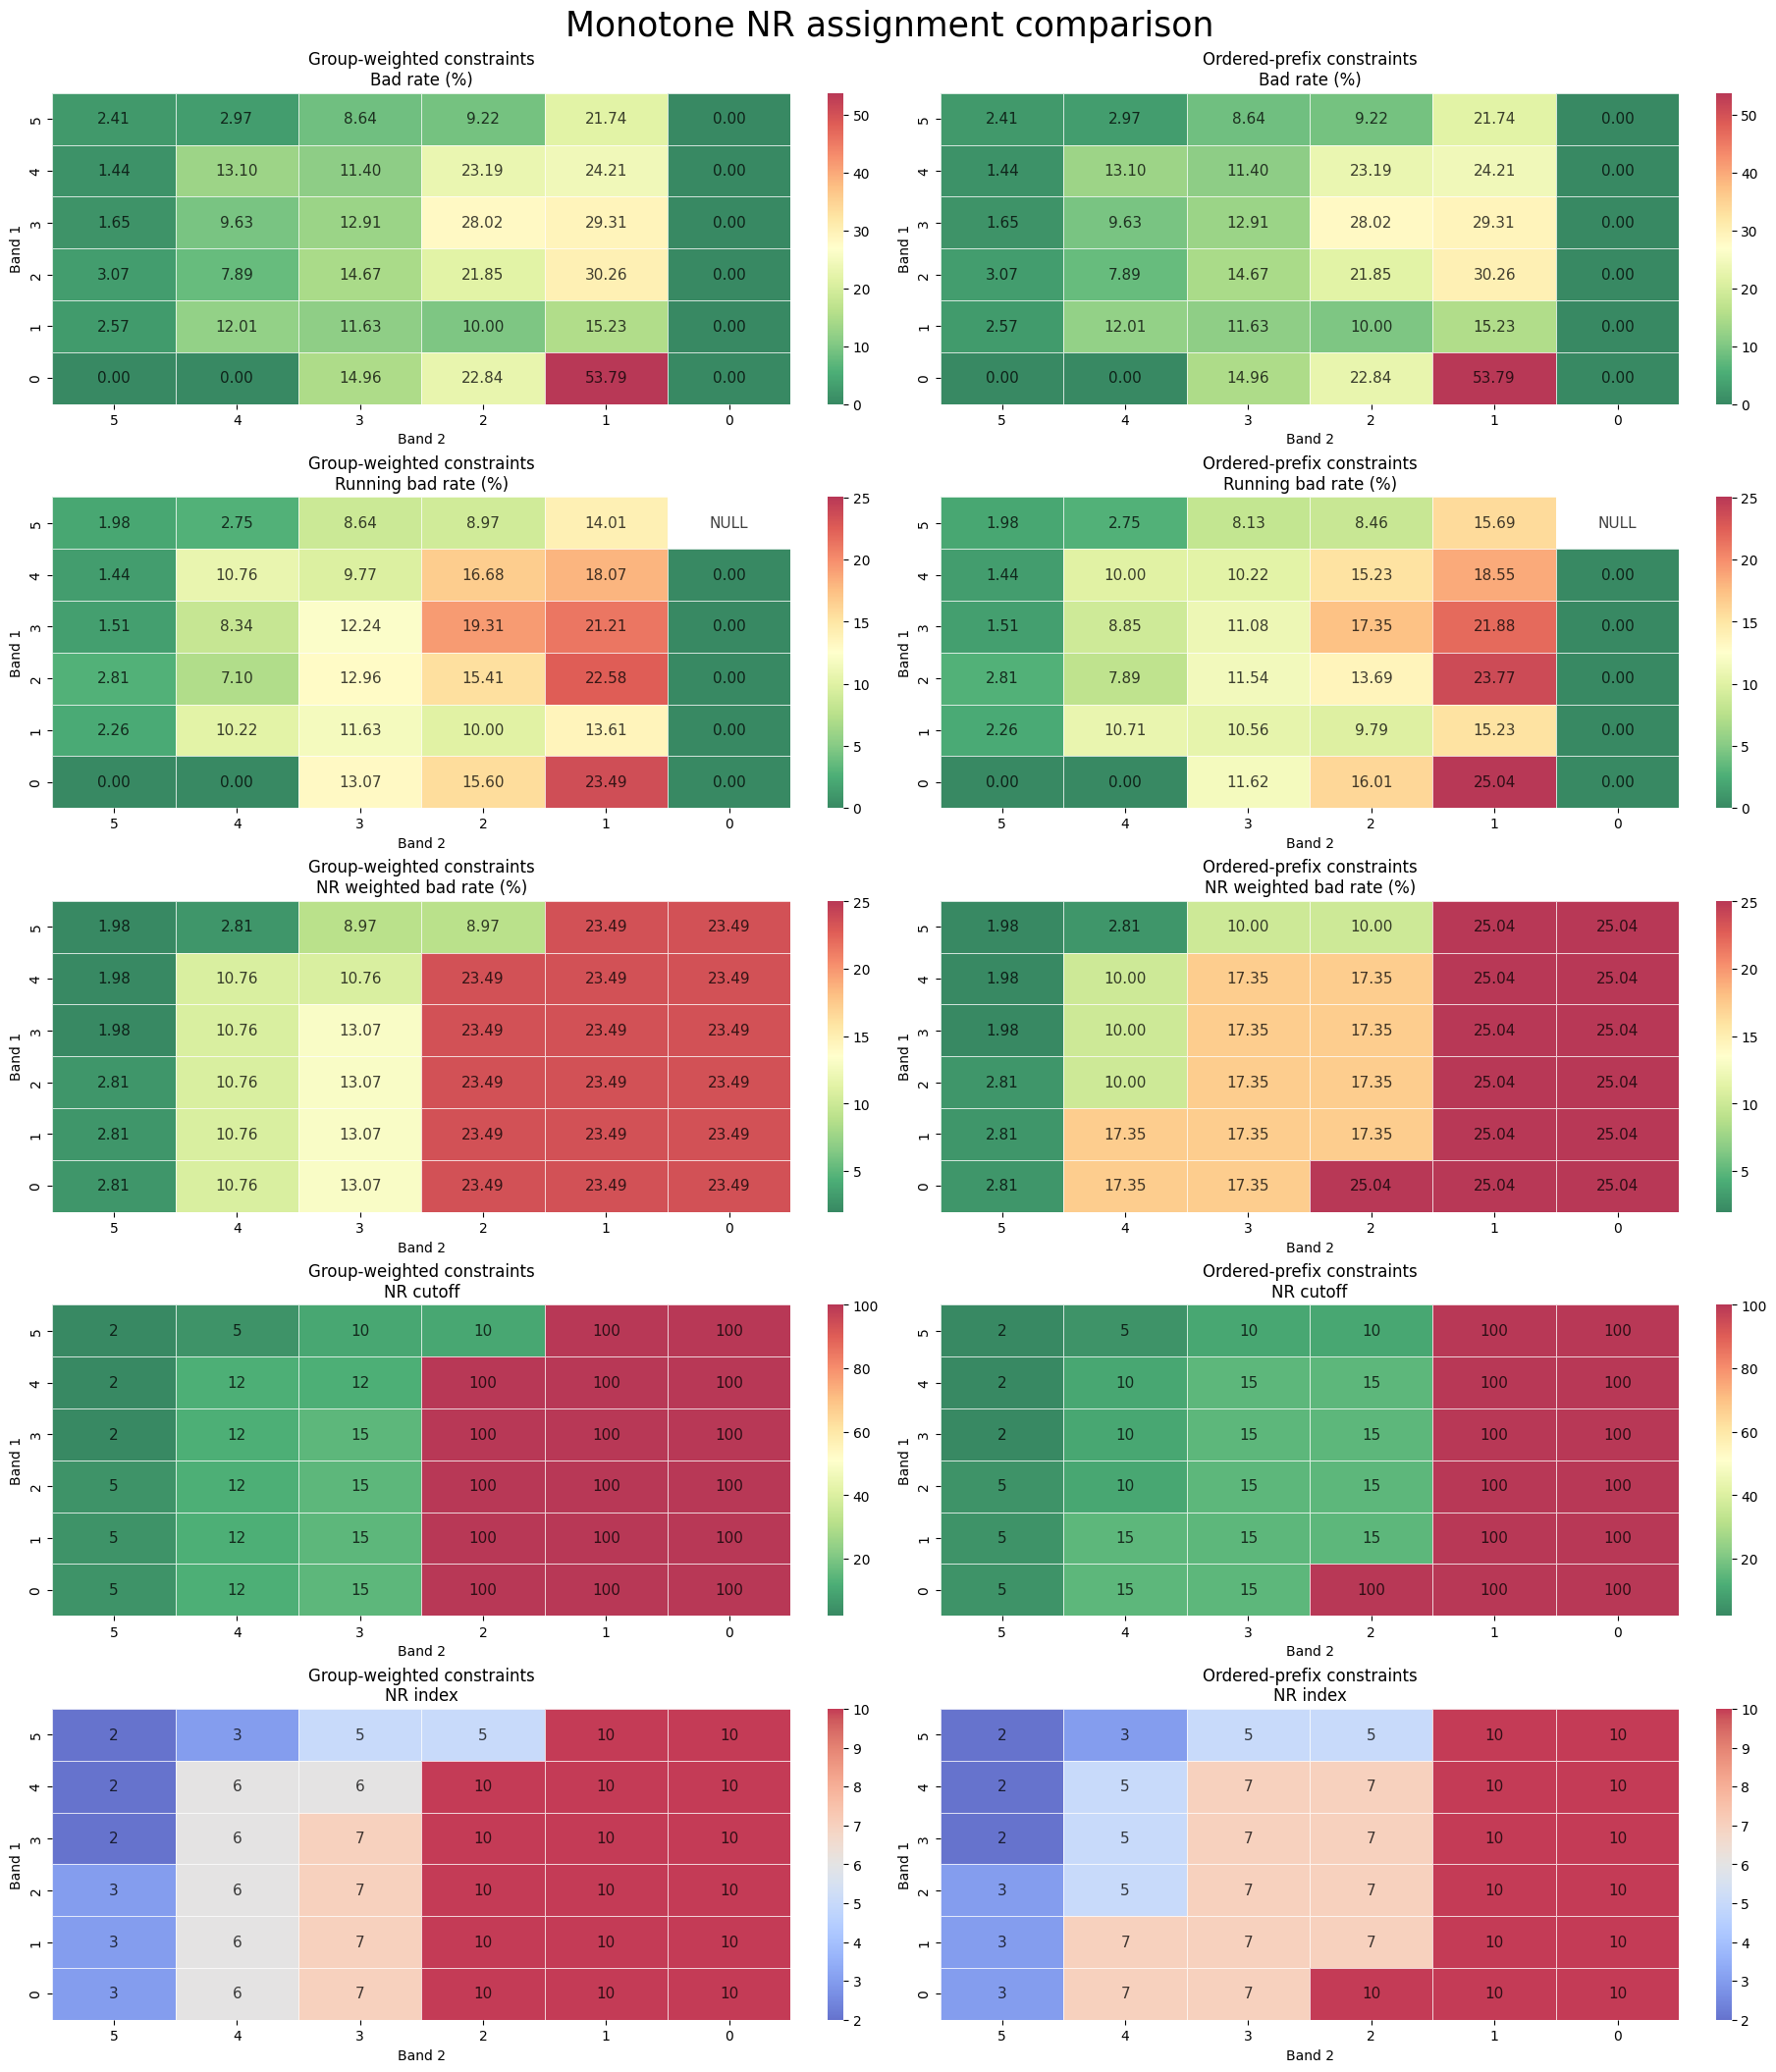

26/11/15 00:31:15 WARN HeartbeatReceiver: Removing executor driver with no recent heartbeats: 686156 ms exceeds timeout 120000 ms
26/11/15 00:31:15 WARN SparkContext: Killing executors is not supported by current scheduler.
26/11/15 00:31:22 WARN Executor: Issue communicating with driver in heartbeater
org.apache.spark.SparkException: Exception thrown in awaitResult: 
	at org.apache.spark.util.SparkThreadUtils$.awaitResult(SparkThreadUtils.scala:56)
	at org.apache.spark.util.ThreadUtils$.awaitResult(ThreadUtils.scala:310)
	at org.apache.spark.rpc.RpcTimeout.awaitResult(RpcTimeout.scala:75)
	at org.apache.spark.rpc.RpcEndpointRef.askSync(RpcEndpointRef.scala:101)
	at org.apache.spark.rpc.RpcEndpointRef.askSync(RpcEndpointRef.scala:85)
	at org.apache.spark.storage.BlockManagerMaster.registerBlockManager(BlockManagerMaster.scala:80)
	at org.apache.spark.storage.BlockManager.reregister(BlockManager.scala:642)
	at org.apache.spark.executor.Executor.reportHeartBeat(Executor.scala:1223)
	at o

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

approaches = {
    "Group-weighted constraints": group_weighted_results,
    "Ordered-prefix constraints": ordered_prefix_results,
}
approach_pdfs = {
    name: result.toPandas()
    for name, result in approaches.items()
}

heatmap_metrics = [
    ("bad_rate", "Bad rate (%)", ".2f", "RdYlGn_r"),
    ("running_bad_rate", "Running bad rate (%)", ".2f", "RdYlGn_r"),
    ("nr_weighted_bad_rate", "NR weighted bad rate (%)", ".2f", "RdYlGn_r"),
    ("NR_cutoff", "NR cutoff", ".0f", "RdYlGn_r"),
    ("NR_index", "NR index", ".0f", "coolwarm"),
]

def shared_limits(metric):
    values = [
        pdf[metric].dropna().to_numpy(dtype=float)
        for pdf in approach_pdfs.values()
    ]
    values = [v for v in values if len(v)]
    if not values:
        return None, None
    all_values = np.concatenate(values)
    return float(all_values.min()), float(all_values.max())

def draw_heatmap(ax, pdf, metric, title, fmt, cmap_name, vmin, vmax):
    matrix = (
        pdf.pivot(index="band_1", columns="band_2", values=metric)
           .sort_index(ascending=False)
           .sort_index(axis=1, ascending=False)
    )

    cmap = plt.get_cmap(cmap_name)
    cmap = cmap.copy()
    cmap.set_bad("white")

    sns.heatmap(
        matrix,
        mask=matrix.isna(),
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        annot=False,
        linewidths=0.6,
        linecolor="white",
        alpha=0.78,
        ax=ax,
    )

    for row_idx, (_, row) in enumerate(matrix.iterrows()):
        for col_idx, value in enumerate(row):
            label = "NULL" if pd.isna(value) else format(value, fmt)
            ax.text(
                col_idx + 0.5,
                row_idx + 0.5,
                label,
                ha="center",
                va="center",
                fontsize=11,
                color="black",
                alpha=0.75,
            )

    ax.set_title(title, fontsize=12)
    ax.set_xlabel("Band 2")
    ax.set_ylabel("Band 1")

fig, axes = plt.subplots(
    nrows=len(heatmap_metrics),
    ncols=len(approach_pdfs),
    figsize=(18, 21),
    constrained_layout=True,
)

for row_idx, (metric, title, fmt, cmap_name) in enumerate(heatmap_metrics):
    vmin, vmax = shared_limits(metric)
    for col_idx, (approach_name, pdf) in enumerate(approach_pdfs.items()):
        draw_heatmap(
            axes[row_idx, col_idx],
            pdf,
            metric,
            f"{approach_name}\n{title}",
            fmt,
            cmap_name,
            vmin,
            vmax,
        )

fig.suptitle("Monotone NR assignment comparison", fontsize=25)
plt.show()